# 12. Inner Products and Orthonormal Bases
Run the cells in order. Keep `lafp.py` in the same folder.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from lafp import *
%matplotlib inline

The orthogonal decomposition behind Cauchy–Schwarz. The vector $u$ splits into its projection $\frac{\langle u,v\rangle}{\lVert v\rVert^2}v$ along $v$ (blue) and a remainder $w\perp v$ (red). The projection is a leg of a right triangle whose hypotenuse is $u$, so it is never longer than $u$: that is the inequality $\lvert\langle u,v\rangle\rvert\le\lVert u\rVert\,\lVert v\rVert$.

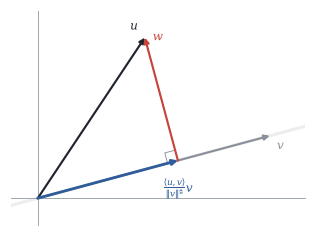

In [2]:
import numpy as np
import matplotlib.pyplot as plt
from lafp import *

u, v = np.array([1.2, 1.8]), np.array([2.6, 0.7])
p = (u @ v) / (v @ v) * v
fig, ax = plt.subplots(figsize=(W * 0.6, 2.1))
plane(ax, (-0.3, 3.0, -0.3, 2.1), grid=False)
span_line(ax, v, lim=3, color=LIGHT, lw=2)
arrow(ax, v, color=GRAY, label="$v$", offset=(0.12, -0.12))
arrow(ax, u, color=INK, label="$u$", offset=(-0.12, 0.12))
arrow(ax, p, color=BLUE, lw=1.8, label=r"$\frac{\langle u,v\rangle}{\|v\|^2}v$", offset=(0.0, -0.32))
arrow(ax, u - p, origin=p, color=RED, label="$w$", offset=(0.15, 0.0))
c = p + 0.12 * (u - p) / np.linalg.norm(u - p); d = c - 0.12 * p / np.linalg.norm(p)
ax.plot([c[0], d[0], d[0] - (c - p)[0]], [c[1], d[1], d[1] - (c - p)[1]], color=GRAY, lw=0.6)

In [3]:
rng = np.random.default_rng(1)
h = rng.normal(170, 8, 200); w = 0.9 * (h - 170) + rng.normal(70, 7, 200)
hc, wc = h - h.mean(), w - w.mean()
cos = hc @ wc / np.linalg.norm(hc) / np.linalg.norm(wc)
print("cos(angle) =", round(cos, 6), "  Pearson r =", round(np.corrcoef(h, w)[0, 1], 6))
print("angle between the centred data vectors:", round(np.degrees(np.arccos(cos)), 2), "degrees")

cos(angle) = 0.741154   Pearson r = 0.741154
angle between the centred data vectors: 42.17 degrees


Unit balls $\{x:\lVert x\rVert\le1\}$ in $\R^2$. Every inner product gives an ellipse (left: the Euclidean circle and the inner products $x^{\mathsf T}Mx$ for two positive definite $M$). The $\ell^p$ norms (right) give circles only for $p=2$; for $p=1$ and $p=\infty$ the balls have corners and the parallelogram law fails.

Text(0.5, 1.0, '$\\ell^p$ norms')

findfont: Failed to find font weight semibold for DejaVu Serif, now using 700.


findfont: Failed to find font weight semibold for DejaVu Serif, now using 700.


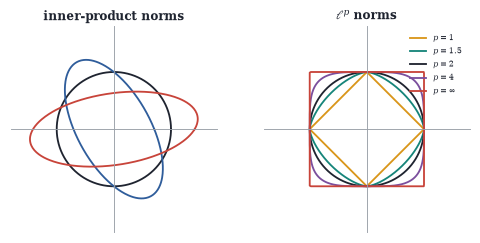

In [4]:
th = np.linspace(0, 2 * np.pi, 400); X = np.vstack([np.cos(th), np.sin(th)])
fig, axs = plt.subplots(1, 2, figsize=(W, 2.1))
ax = plane(axs[0], 1.8, grid=False)
for M, col in [(np.eye(2), INK), (np.array([[2.0, 0.8], [0.8, 1.0]]), BLUE), (np.array([[0.5, -0.3], [-0.3, 2.5]]), RED)]:
    r = 1 / np.sqrt(np.einsum("ij,ik,kj->j", X, M, X)); ax.plot(*(X * r), color=col)
ax.set_title("inner-product norms")
ax = plane(axs[1], 1.8, grid=False)
for pp, col in [(1, GOLD), (1.5, TEAL), (2, INK), (4, PLUM), (np.inf, RED)]:
    nrm = np.max(np.abs(X), 0) if pp == np.inf else (np.abs(X[0]) ** pp + np.abs(X[1]) ** pp) ** (1 / pp)
    ax.plot(*(X / nrm), color=col, label=f"$p={pp}$" if pp != np.inf else r"$p=\infty$")
ax.legend(fontsize=5.5, loc="upper right"); ax.set_title(r"$\ell^p$ norms")

Cosines of the angles between $20{,}000$ pairs of independent random unit vectors in $\R^d$. In two dimensions all angles are equally likely; as $d$ grows the distribution concentrates sharply around $0$ (orthogonality), with spread about $1/\sqrt d$.

(0.01, 20)

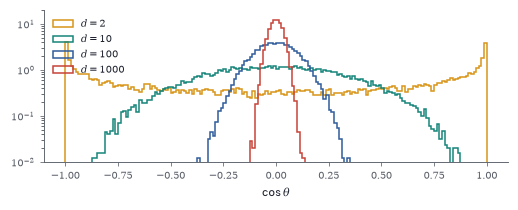

In [5]:
rng = np.random.default_rng(0)
fig, ax = plt.subplots(figsize=(W, 1.8))
for d, col in [(2, GOLD), (10, TEAL), (100, BLUE), (1000, RED)]:
    x = rng.normal(size=(20000, d)); y = rng.normal(size=(20000, d))
    c = np.einsum("ij,ij->i", x, y) / np.linalg.norm(x, axis=1) / np.linalg.norm(y, axis=1)
    ax.hist(c, bins=np.linspace(-1, 1, 161), density=True, histtype="step", color=col, label=f"$d={d}$")
ax.set_xlabel(r"$\cos\theta$"); ax.legend(); ax.set_yscale("log"); ax.set_ylim(1e-2, 20)

Three orthonormal bases of $\R^8$, each drawn as an $8\times8$ matrix whose columns are the basis vectors (blue positive, red negative). The Hadamard–Walsh basis uses only $\pm1/\sqrt8$; the Haar wavelets are localized differences at successive scales; the discrete cosine basis (used in JPEG) oscillates with increasing frequency. In each case $Q^{\mathsf T}Q=I$.

findfont: Failed to find font weight semibold for DejaVu Serif, now using 700.


Hadamard–Walsh   max |Q^T Q - I| = 1.1e-16
Haar             max |Q^T Q - I| = 2.2e-16
discrete cosine  max |Q^T Q - I| = 1.4e-15


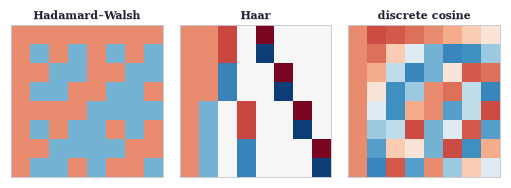

In [6]:
from scipy.linalg import hadamard
n = 8
H = hadamard(n) / np.sqrt(n)
def haar(n):
    if n == 1: return np.ones((1, 1))
    h = haar(n // 2)
    top = np.kron(h, [1, 1]); bot = np.kron(np.eye(n // 2), [1, -1])
    M = np.vstack([top, bot]); return M / np.linalg.norm(M, axis=1, keepdims=True)
Hr = haar(n).T
k = np.arange(n)
C = np.cos(np.pi * (k[:, None] + 0.5) * k[None, :] / n); C /= np.linalg.norm(C, axis=0)
fig, axs = plt.subplots(1, 3, figsize=(W, 1.6))
for ax, M, t in zip(axs, [H, Hr, C], ["Hadamard–Walsh", "Haar", "discrete cosine"]):
    heat(ax, M, annot=False, vmax=0.75); ax.set_title(t, fontsize=7)
    print(f"{t:16s} max |Q^T Q - I| = {np.abs(M.T @ M - np.eye(n)).max():.1e}")

Gram–Schmidt in $\R^3$. Left, an independent but skewed basis $v_1,v_2,v_3$. Right, the orthonormal basis $e_1,e_2,e_3$ it produces: $e_1$ points along $v_1$; $e_2$ lies in the plane of $v_1,v_2$ (shaded) perpendicular to $e_1$; $e_3$ is perpendicular to that plane.

E^T E =
 [[ 1.  0. -0.]
 [ 0.  1. -0.]
 [-0. -0.  1.]]


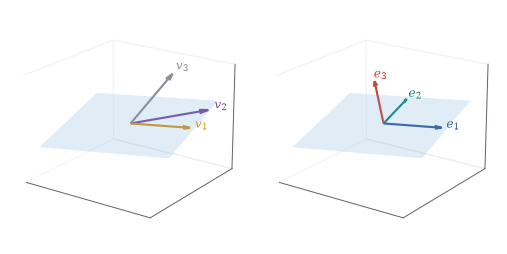

In [7]:
Vb = np.array([[1.0, 0.2, 0.1], [0.9, 0.9, 0.2], [0.4, 0.6, 1.0]]).T
def gram_schmidt(V):
    E = []
    for v in V.T:
        f = v - sum((v @ e) * e for e in E)
        E.append(f / np.linalg.norm(f))
    return np.array(E).T
E = gram_schmidt(Vb)
fig = plt.figure(figsize=(W, 2.2))
for k, (M, lab, col) in enumerate([(Vb, "v", GOLD), (E, "e", BLUE)]):
    ax = ax3d(fig, pos=121 + k, elev=20, azim=-55, lim=1.2)
    s, r = np.meshgrid([-1.1, 1.1], [-1.1, 1.1]); P = s[..., None] * E[:, 0] + r[..., None] * E[:, 1]
    ax.plot_surface(P[..., 0], P[..., 1], P[..., 2], color=SKY, alpha=0.2, lw=0, shade=False)
    for j in range(3):
        arrow3d(ax, M[:, j], color=[col, TEAL, RED][j] if lab == "e" else [GOLD, PLUM, GRAY][j], label=f"${lab}_{j+1}$")
    ax.set_xticks([]); ax.set_yticks([]); ax.set_zticks([])
print("E^T E =\n", (E.T @ E).round(12))

Gram–Schmidt applied to $1,x,\dots,x^5$ with $\langle p,q\rangle=\int_{-1}^1pq$ produces the normalized Legendre polynomials (computed here numerically by quadrature). Each has one more zero than the last, all inside $(-1,1)$, interlacing with the zeros of its predecessor.

(-2.6, 3.0)

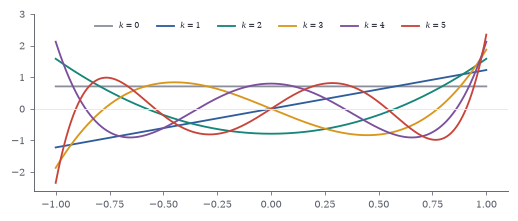

In [8]:
x = np.linspace(-1, 1, 2001); w = np.full_like(x, x[1] - x[0]); w[[0, -1]] /= 2
ip = lambda f, g: np.sum(f * g * w)
P = []
for k in range(6):
    f = x ** k
    for e in P:
        f = f - ip(f, e) * e
    P.append(f / np.sqrt(ip(f, f)))
fig, ax = plt.subplots(figsize=(W, 1.9))
for k, (pk, col) in enumerate(zip(P, [GRAY, BLUE, TEAL, GOLD, PLUM, RED])):
    ax.plot(x, pk, color=col, label=f"$k={k}$")
ax.axhline(0, color=LIGHT, lw=0.6); ax.legend(ncol=6, fontsize=5.5, loc="upper center"); ax.set_ylim(-2.6, 3.0)

Loss of orthogonality $\lVert Q^{\mathsf T}Q-I\rVert$ for classical Gram–Schmidt (red), modified Gram–Schmidt (gold) and Householder QR (blue, numpy) applied to $30\times10$ matrices of increasing condition number. Classical GS degrades like $\kappa^2\varepsilon$ and fails completely near $\kappa=10^8$; Householder stays at $\varepsilon$.

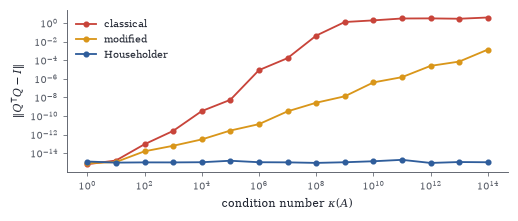

In [9]:
def cgs(A):
    Q = np.zeros_like(A)
    for k in range(A.shape[1]):
        v = A[:, k] - Q[:, :k] @ (Q[:, :k].T @ A[:, k]); Q[:, k] = v / np.linalg.norm(v)
    return Q
def mgs(A):
    Q = A.copy()
    for k in range(A.shape[1]):
        Q[:, k] /= np.linalg.norm(Q[:, k])
        Q[:, k + 1:] -= np.outer(Q[:, k], Q[:, k] @ Q[:, k + 1:])
    return Q
rng = np.random.default_rng(1)
U, _ = np.linalg.qr(rng.normal(size=(30, 10))); V, _ = np.linalg.qr(rng.normal(size=(10, 10)))
kappas = 10.0 ** np.arange(0, 15)
res = {"classical": [], "modified": [], "Householder": []}
for kap in kappas:
    A = U @ np.diag(np.logspace(0, -np.log10(kap), 10)) @ V.T
    for name, f in [("classical", cgs), ("modified", mgs), ("Householder", lambda A: np.linalg.qr(A)[0])]:
        Q = f(A); res[name].append(np.linalg.norm(Q.T @ Q - np.eye(10)))
fig, ax = plt.subplots(figsize=(W, 1.9))
for name, col in [("classical", RED), ("modified", GOLD), ("Householder", BLUE)]:
    ax.loglog(kappas, res[name], "o-", ms=3, color=col, label=name)
ax.set_xlabel(r"condition number $\kappa(A)$"); ax.set_ylabel(r"$\|Q^{\mathsf{T}}Q-I\|$"); ax.legend()

The gradient depends on the inner product. Level sets of $f(x)=x_1^2+6x_2^2$ (grey). At the marked point, the Euclidean gradient (red) is perpendicular to the level set in the usual sense and points far from the minimum; the gradient for the inner product defined by the Hessian (blue) points straight at the minimum. Both represent the same derivative.

(np.float64(-2.2), np.float64(2.2), np.float64(-1.2), np.float64(1.2))

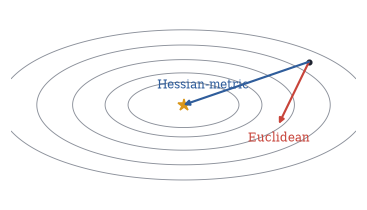

In [10]:
H = np.diag([2.0, 12.0])
xx, yy = np.meshgrid(np.linspace(-2.2, 2.2, 300), np.linspace(-1.2, 1.2, 300))
fig, ax = plt.subplots(figsize=(W * 0.7, 1.9))
ax.contour(xx, yy, xx ** 2 + 6 * yy ** 2, levels=[0.5, 1, 2, 3.5, 5.5], colors=[GRAY], linewidths=0.6)
x0 = np.array([1.6, 0.55]); g = H @ x0
arrow(ax, -0.12 * g, origin=x0, color=RED, label="Euclidean", offset=(0.0, -0.18))
arrow(ax, -np.linalg.solve(H, g), origin=x0, color=BLUE, label="Hessian-metric", offset=(0.25, 0.25))
ax.plot(*x0, "o", color=INK, ms=3); ax.plot(0, 0, "*", color=GOLD, ms=8); ax.set_aspect("equal"); ax.axis("off")

The functional $\varphi(x)=x_1+2x_2$ as a family of parallel level lines $\varphi=c$. Its Euclidean representer $u=(1,2)$ (blue) is perpendicular to them and has length $1/\text{spacing}$. In the inner product $\langle x,y\rangle_M=y^{\mathsf T}Mx$ the representer is $M^{-1}u$ (red): a different arrow for the same stack of lines, still crossing one unit of $\varphi$ per unit of $M$-length squared.

(np.float64(-2.5), np.float64(2.6), np.float64(-1.6), np.float64(2.4))

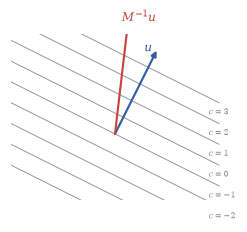

In [11]:
fig, ax = plt.subplots(figsize=(W * 0.62, 2.0))
xs = np.linspace(-2.5, 2.5, 2)
for c in range(-4, 5):
    ax.plot(xs, (c - xs) / 2, color=GRAY, lw=0.6)
    if -2 <= c <= 3: ax.text(2.25, (c - 2.25) / 2 + 0.08, f"$c={c}$", fontsize=5.5, color=GRAY)
u = np.array([1.0, 2.0]); M = np.array([[3.0, 0.0], [0.0, 0.7]])
arrow(ax, u, color=BLUE, label=r"$u$", offset=(-0.2, 0.05))
arrow(ax, np.linalg.solve(M, u), color=RED, label=r"$M^{-1}u$", offset=(0.25, -0.05))
ax.set_xlim(-2.5, 2.6); ax.set_ylim(-1.6, 2.4); ax.set_aspect("equal"); ax.axis("off")

Fourier partial sums of the square wave $f=\operatorname{sign}(x)$ on $[-\pi,\pi]$ (left) and the accumulated energy $\sum$ (coefficients$^2$) approaching $\lVert f\rVert^2=2\pi$ from below, as Bessel's inequality says it must (right). The overshoot near the jump (Gibbs phenomenon) does not shrink, yet the squared error does.

Text(30, 5.683185307179587, '$\\|f\\|^2=2\\pi$')

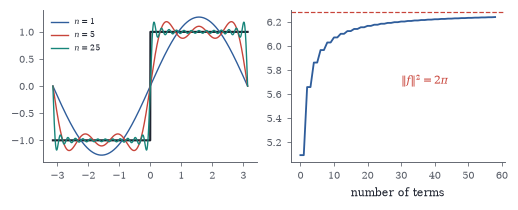

In [12]:
x = np.linspace(-np.pi, np.pi, 2000); f = np.sign(x); dx = x[1] - x[0]
fig, axs = plt.subplots(1, 2, figsize=(W, 1.8))
axs[0].plot(x, f, color=INK, lw=1.4)
energy, Sn = [], np.zeros_like(x)
for k in range(1, 60):
    bk = np.sum(f * np.sin(k * x)) * dx / np.sqrt(np.pi)
    Sn = Sn + bk * np.sin(k * x) / np.sqrt(np.pi); energy.append(bk ** 2)
    if k in (1, 5, 25):
        axs[0].plot(x, Sn, lw=0.9, label=f"$n={k}$")
axs[0].legend(fontsize=5.5)
axs[1].plot(np.cumsum(energy), color=BLUE); axs[1].axhline(2 * np.pi, color=RED, ls="--", lw=0.8)
axs[1].set_xlabel("number of terms"); axs[1].text(30, 2 * np.pi - 0.6, r"$\|f\|^2=2\pi$", color=RED, fontsize=7)

In [13]:
H = np.array([[1 / (j + k + 1) for k in range(3)] for j in range(3)])
print("q for p(1/2):", np.linalg.solve(H, [1, 1 / 2, 1 / 4]))
m = [0, -2 / np.pi ** 2, -2 / np.pi ** 2]
print("q for cos(pi x):", np.linalg.solve(H, m), " vs (12, -24, 0)/pi^2:", np.array([12, -24, 0]) / np.pi ** 2)

q for p(1/2): [ -1.5  15.  -15. ]
q for cos(pi x): [ 1.21585420e+00 -2.43170841e+00  1.21488240e-14]  vs (12, -24, 0)/pi^2: [ 1.2158542  -2.43170841  0.        ]


In [14]:
F = np.array([[1j ** (j * k) for j in range(4)] for k in range(4)])
P = np.roll(np.eye(4), -1, axis=0)                      # (P x)_k = x_{k+1}
print("P x_j = i^j x_j:", all(np.allclose(P @ F[:, j], 1j ** j * F[:, j]) for j in range(4)))
print("Q* Q = I:", np.allclose((F / 2).conj().T @ (F / 2), np.eye(4)))

P x_j = i^j x_j: True
Q* Q = I: True


The eight unnormalized Haar wavelets in $\R^8$, from the coarsest (constant) to the finest scale. Each is orthogonal to all the others.

W^T W = [8. 8. 4. 4. 2. 2. 2. 2.]  off-diagonal max: 0.0


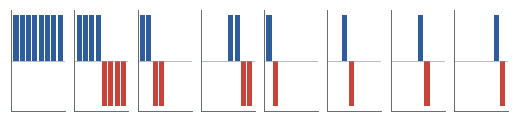

In [15]:
Wh = np.zeros((8, 8)); Wh[:, 0] = 1; Wh[:4, 1], Wh[4:, 1] = 1, -1
Wh[:2, 2], Wh[2:4, 2] = 1, -1; Wh[4:6, 3], Wh[6:, 3] = 1, -1
for k in range(4):
    Wh[2 * k, 4 + k], Wh[2 * k + 1, 4 + k] = 1, -1
fig, axs = plt.subplots(1, 8, figsize=(W, 1.0), sharey=True)
for k, ax in enumerate(axs):
    ax.bar(range(8), Wh[:, k], color=[BLUE if v > 0 else RED for v in Wh[:, k]], width=0.8)
    ax.set_xticks([]); ax.set_yticks([]); ax.axhline(0, color=GRAY, lw=0.4)
print("W^T W =", np.diag(Wh.T @ Wh), " off-diagonal max:", np.abs(Wh.T @ Wh - np.diag(np.diag(Wh.T @ Wh))).max())